# Medical Supply Chain Analytics: Delivery and Cost Analysis

## Project Objective


The main objective of this project is to analyze medical supply chain data and understand the factors and patterns associated with shipment delivery and logistics costs.

The project aims to:

- Understand the structure and characteristics of the medical supply chain dataset.
- Clean and prepare the data for analysis.
- Analyze shipment and delivery performance.
- Study shipment patterns across countries, vendors, product groups, and transportation methods.
- Analyze the relationship between shipment quantities, product prices, and freight costs.
- Identify important patterns, trends, and unusual observations in the dataset.
- Use suitable visualizations to communicate the findings.
- Generate meaningful insights from the complete dataset.

##  Dataset Description


The dataset contains information about medical product shipments, including shipment dates, countries, vendors, product details, transportation methods, quantities, and logistics costs.

Important variables in the dataset include:

- ID — Unique identification number for each shipment record.
- Project Code — Code identifying the project associated with the shipment.
- PQ # — Purchase quotation reference number.
- PO / SO # — Purchase order or sales order reference number.
- ASN/DN # — Advanced shipping notice or delivery note reference number.
- Country — Country associated with the shipment.
- Managed By — Organization or entity managing the shipment.
- Fulfill Via — Method used to fulfill the order.
- Vendor INCO Term — International commercial term agreed upon with the vendor.
- Shipment Mode — Transportation method used for shipping.
- PQ First Sent to Client Date — Date the purchase quotation was first sent to the client.
- PO Sent to Vendor Date — Date the purchase order was sent to the vendor.
- Scheduled Delivery Date — Planned delivery date of the shipment.
- Delivered to Client Date — Date the shipment was delivered to the client.
- Delivery Recorded Date — Date the delivery was recorded in the system.
- Product Group — Category of the medical product.
- Sub Classification — Subcategory of the product.
- Vendor — Supplier responsible for providing the products.
- Item Description — Description of the medical product.
- Molecule/Test Type — Molecule or test type associated with the product.
- Brand — Brand name of the product.
- Dosage — Dosage strength or amount of the product.
- Dosage Form — Form in which the product is supplied.
- Unit of Measure (Per Pack) — Measurement unit used for each package.
- Line Item Quantity — Number of product units ordered or shipped.
- Line Item Value — Total value of the line item.
- Pack Price — Price of one package of the product.
- Unit Price — Price per individual unit.
- Manufacturing Site — Location where the product was manufactured.
- First Line Designation — Indicates whether the product is designated as a first-line treatment or product.
- Weight (Kilograms) — Weight of the shipment in kilograms.
- Freight Cost (USD) — Transportation cost of the shipment in US dollars.
- Line Item Insurance (USD) — Insurance cost associated with the line item in US dollars.

## EDA Process

The following stages will be followed throughout the project:

1. Data Collection
2. Data Cleaning
3. Data Understanding
4. Data Preparation
5. Univariate Analysis
6. Bivariate Analysis
7. Multivariate Analysis
8. Feature Engineering
9. Statistical Analysis
10. Outlier Detection
11. Trend and Pattern Analysis
12. Data Visualization
13. Key Insights
14. Conclusion

## Import the Necessary Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [3]:
df = pd.read_csv("shipment_data.csv")

## Display the First 5 Rows

In [8]:
df.head()

,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,02-Jun-06,02-Jun-06,02-Jun-06,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,14-Nov-06,14-Nov-06,14-Nov-06,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,27-Aug-06,27-Aug-06,27-Aug-06,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,01-Sep-06,01-Sep-06,01-Sep-06,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,11-Aug-06,11-Aug-06,11-Aug-06,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


## Display the Last 5 Rows

In [5]:
df.tail()

,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
10319,31-Jul-15,15-Jul-15,20-Jul-15,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,...,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",No,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,31-Jul-15,06-Aug-15,07-Aug-15,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,...,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,No,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,31-Aug-15,25-Aug-15,03-Sep-15,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,...,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,No,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,09-Sep-15,04-Aug-15,11-Aug-15,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,...,60,17465,113871.80,6.52,0.11,Mylan (formerly Matrix) Nashik,Yes,1392,Freight Included in Commodity Cost,134.03
10323,31-Aug-15,04-Aug-15,11-Aug-15,86823,103-ZW-T30,FPQ-15197,SO-50022,DN-4336,Zimbabwe,PMO - US,...,60,36639,72911.61,1.99,0.03,"Cipla, Goa, India",No,Weight Captured Separately,Freight Included in Commodity Cost,85.82


## Check Dataset Information

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Scheduled Delivery Date       10324 non-null  object 
 1   Delivered to Client Date      10324 non-null  object 
 2   Delivery Recorded Date        10324 non-null  object 
 3   ID                            10324 non-null  int64  
 4   Project Code                  10324 non-null  object 
 5   PQ #                          10324 non-null  object 
 6   PO / SO #                     10324 non-null  object 
 7   ASN/DN #                      10324 non-null  object 
 8   Country                       10324 non-null  object 
 9   Managed By                    10324 non-null  object 
 10  Fulfill Via                   10324 non-null  object 
 11  Vendor INCO Term              10324 non-null  object 
 12  Shipment Mode                 9964 non-null   object 
 13  P

## Describe the Dataset

In [7]:
df.describe()

,ID,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Line Item Insurance (USD)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


## Check for Missing Values

In [8]:
df.isnull().sum()

Scheduled Delivery Date            0
Delivered to Client Date           0
Delivery Recorded Date             0
ID                                 0
Project Code                       0
PQ #                               0
PO / SO #                          0
ASN/DN #                           0
Country                            0
Managed By                         0
Fulfill Via                        0
Vendor INCO Term                   0
Shipment Mode                    360
PQ First Sent to Client Date       0
PO Sent to Vendor Date             0
Product Group                      0
Sub Classification                 0
Vendor                             0
Item Description                   0
Molecule/Test Type                 0
Brand                              0
Dosage                          1736
Dosage Form                        0
Unit of Measure (Per Pack)         0
Line Item Quantity                 0
Line Item Value                    0
Pack Price                         0
U

## Check for Duplicate Values

In [9]:
df.duplicated().sum()

0

## Converting Date Columns to Datetime

In [4]:
df['PQ First Sent to Client Date'] = pd.to_datetime(df['PQ First Sent to Client Date'], errors='coerce')
df['PO Sent to Vendor Date'] = pd.to_datetime(df['PO Sent to Vendor Date'], errors='coerce')
df['Scheduled Delivery Date'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce')
df['Delivered to Client Date'] = pd.to_datetime(df['Delivered to Client Date'], errors='coerce')
df['Delivery Recorded Date'] = pd.to_datetime(df['Delivery Recorded Date'], errors='coerce')

## Check Data Types

In [5]:
df.dtypes

Scheduled Delivery Date         datetime64[ns]
Delivered to Client Date        datetime64[ns]
Delivery Recorded Date          datetime64[ns]
ID                                       int64
Project Code                            object
PQ #                                    object
PO / SO #                               object
ASN/DN #                                object
Country                                 object
Managed By                              object
Fulfill Via                             object
Vendor INCO Term                        object
Shipment Mode                           object
PQ First Sent to Client Date    datetime64[ns]
PO Sent to Vendor Date          datetime64[ns]
Product Group                           object
Sub Classification                      object
Vendor                                  object
Item Description                        object
Molecule/Test Type                      object
Brand                                   object
Dosage       

## Check for Suspicious or Invalid Values

In [14]:
#Negative Line Item Quantity check
print('Line Item Quantity:', (df['Line Item Quantity']<0).sum())

Line Item Quantity: 0


In [15]:
#Negative Line Item Value check
print('Line Item Value:', (df['Line Item Value']<0).sum())

Line Item Value: 0


In [16]:
#Negative Pack Price check
print('Pack Price:', (df['Pack Price']<0).sum())

Pack Price: 0


In [17]:
#Negative Unit Price check
print('Unit Price:', (df['Unit Price']<0).sum())

Unit Price: 0


In [17]:
#Check Weight column values
print(df['Weight (Kilograms)'].head(10))
print(df['Weight (Kilograms)'].dtype)

0                       13
1                      358
2                      171
3                     1855
4                     7590
5                      504
6                      328
7                     1478
8    See ASN-93 (ID#:1281)
9                      643
Name: Weight (Kilograms), dtype: object
object


In [5]:
#Convert Weight column to numeric
df['Weight (Kilograms)'] = pd.to_numeric(df['Weight (Kilograms)'], errors='coerce')

In [21]:
#Negative Weight check
print('Weight (Kilograms):', (df['Weight (Kilograms)']<0).sum())

Weight (Kilograms): 0


In [7]:
#Convert Freight Cost column to numeric
df['Freight Cost (USD)'] = pd.to_numeric(df['Freight Cost (USD)'], errors='coerce')

In [24]:
#Negative Freight Cost check
print('Freight Cost (USD):', (df['Freight Cost (USD)']<0).sum())

Freight Cost (USD): 0


In [25]:
#Negative Line Item Insurance check
print('Line Item Insurance (USD):', (df['Line Item Insurance (USD)']<0).sum())

Line Item Insurance (USD): 0


## Data Cleaning Done

## Basic Calculation on Dataset

In [26]:
#1 Calculate the total number of shipment records in the dataset.
df.shape[0]

10324

In [29]:
#2 How many unique suppliers, vendors, countries, and product groups are present?
print("Unique Suppliers:", df['Manufacturing Site'].nunique())
print("Unique Vendors:", df['Vendor'].nunique())
print("Unique Countries:", df['Country'].nunique())
print("Unique Product Groups:", df['Product Group'].nunique())

Unique Suppliers: 88
Unique Vendors: 73
Unique Countries: 43
Unique Product Groups: 5


In [30]:
#3 Calculate the overall average, minimum, maximum, median, and standard deviation of Freight Cost.
df['Freight Cost (USD)'].describe()

count      6198.000000
mean      11103.234819
std       15813.026692
min           0.750000
25%        2131.120000
50%        5869.655000
75%       14406.570000
max      289653.200000
Name: Freight Cost (USD), dtype: float64

In [ ]:
#4 Calculate the percentage of shipments with freight costs between 100 and 500 USD.
((df['Freight Cost (USD)'] >= 100) & (df['Freight Cost (USD)'] <= 500)).sum() / df['Freight Cost (USD)'].notna().sum() * 100

2.936431106808648

In [ ]:
#5 Count the number of shipments handled by each shipment mode.
df['Shipment Mode'].value_counts()

Air            6113
Truck          2830
Air Charter     650
Ocean           371
Name: Shipment Mode, dtype: int64

In [35]:
#6 Calculate the average freight cost and compare it with the average insurance cost.
average_freight_cost = df['Freight Cost (USD)'].mean()
average_insurance_cost = df['Line Item Insurance (USD)'].mean()

print('Average Freight Cost:', average_freight_cost)
print('Average Insurance Cost:', average_insurance_cost)

freight_high = df[df['Line Item Insurance (USD)'] > 0]['Freight Cost (USD)'].mean()
freight_no_insurance = df[df['Line Item Insurance (USD)'] == 0]['Freight Cost (USD)'].mean()

print("Average Freight Cost - Shipments with Insurance:", freight_high)
print("Average Freight Cost - Shipments without Insurance:", freight_no_insurance)

Average Freight Cost: 11103.234819296547
Average Insurance Cost: 240.11762578459698
Average Freight Cost - Shipments with Insurance: 11274.592396390375
Average Freight Cost - Shipments without Insurance: 7910.668636363637


## Date and Time Analysis

In [16]:
#7 Extract the Year, Month, Day, Day Name, and Week Number from Scheduled Delivery Date.
df['year'] = df['Scheduled Delivery Date'].dt.year
df['Month'] = df['Scheduled Delivery Date'].dt.month
df['Day'] = df['Scheduled Delivery Date'].dt.day
df['Day_Name'] = df['Scheduled Delivery Date'].dt.day_name()
df['Week_Number'] = df['Scheduled Delivery Date'].dt.isocalendar().week

In [8]:
df[['Scheduled Delivery Date', 'year', 'Month', 'Day', 'Day_Name', 'Week_Number']]

,Scheduled Delivery Date,year,Month,Day,Day_Name,Week_Number
0,2006-06-02,2006,6,2,Friday,22
1,2006-11-14,2006,11,14,Tuesday,46
2,2006-08-27,2006,8,27,Sunday,34
3,2006-09-01,2006,9,1,Friday,35
4,2006-08-11,2006,8,11,Friday,32
...,...,...,...,...,...,...
10319,2015-07-31,2015,7,31,Friday,31
10320,2015-07-31,2015,7,31,Friday,31
10321,2015-08-31,2015,8,31,Monday,36
10322,2015-09-09,2015,9,9,Wednesday,37


In [17]:
#8 Extract the Year, Month, Day, Day Name, and Week Number from Delivered to Client Date.
df['Delivered_Year'] = df['Delivered to Client Date'].dt.year
df['Delivered_Month'] = df['Delivered to Client Date'].dt.month
df['Delivered_Day'] = df['Delivered to Client Date'].dt.day
df['Delivered_Day_Name'] = df['Delivered to Client Date'].dt.day_name()
df['Delivered_Week_Number'] = df['Delivered to Client Date'].dt.isocalendar().week

In [10]:
df[['Delivered to Client Date', 'Delivered_Year', 'Delivered_Month',
    'Delivered_Day', 'Delivered_Day_Name', 'Delivered_Week_Number']]

,Delivered to Client Date,Delivered_Year,Delivered_Month,Delivered_Day,Delivered_Day_Name,Delivered_Week_Number
0,2006-06-02,2006,6,2,Friday,22
1,2006-11-14,2006,11,14,Tuesday,46
2,2006-08-27,2006,8,27,Sunday,34
3,2006-09-01,2006,9,1,Friday,35
4,2006-08-11,2006,8,11,Friday,32
...,...,...,...,...,...,...
10319,2015-07-15,2015,7,15,Wednesday,29
10320,2015-08-06,2015,8,6,Thursday,32
10321,2015-08-25,2015,8,25,Tuesday,35
10322,2015-08-04,2015,8,4,Tuesday,32


In [15]:
#9 Calculate the total number of shipments scheduled in each month.
df.groupby('Month')['ID'].count()

Month
1      716
2      719
3     1001
4      963
5      805
6      951
7      917
8     1081
9      884
10     822
11     785
12     680
Name: ID, dtype: int64

In [20]:
#10 Calculate and compare the average freight cost for each shipment mode.

average_freight_cost = df.groupby('Shipment Mode')['Freight Cost (USD)'].mean()

print("Average Freight Cost by Shipment Mode:")
print(average_freight_cost)

print("\nShipment Mode with Highest Average Freight Cost:")
print(average_freight_cost.idxmax())

print("\nHighest Average Freight Cost:")
print(average_freight_cost.max())

Average Freight Cost by Shipment Mode:
Shipment Mode
Air            10458.960753
Air Charter    21052.142642
Ocean          12733.080816
Truck          10176.405000
Name: Freight Cost (USD), dtype: float64

Shipment Mode with Highest Average Freight Cost:
Air Charter

Highest Average Freight Cost:
21052.142641509436


In [21]:
#11 Calculate the average quantity of medical supplies shipped through each shipment mode.
average_quantity = df.groupby('Shipment Mode')['Line Item Quantity'].mean()

print("Average Quantity by Shipment Mode:")
print(average_quantity)

print("\nShipment Mode with Highest Average Quantity:")
print(average_quantity.idxmax())

print("\nHighest Average Quantity:")
print(average_quantity.max())

Average Quantity by Shipment Mode:
Shipment Mode
Air             9143.640275
Air Charter    45352.953846
Ocean          65314.692722
Truck          26803.161484
Name: Line Item Quantity, dtype: float64

Shipment Mode with Highest Average Quantity:
Ocean

Highest Average Quantity:
65314.69272237197


In [ ]:
#12 Calculate the total Line Item Value for each vendor and identify the vendor with the highest total value.

vendor_total_value = df.groupby('Vendor')['Line Item Value'].sum()

print("Total Line Item Value by Vendor:")
print(vendor_total_value)

print("\nVendor with Highest Total Line Item Value:")
print(vendor_total_value.idxmax())

print("\nHighest Total Line Item Value:")
print(vendor_total_value.max())

Total Line Item Value by Vendor:
Vendor
ABBOTT LABORATORIES (PUERTO RICO)                                 224625.27
ABBOTT LOGISTICS B.V.                                             203371.58
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)                 29448061.22
ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTERNATIONAL CO.)      205850.80
ACCESS BIO, INC.                                                   50520.60
                                                                   ...     
THE MEDICAL EXPORT GROUP BV                                       100540.00
TURE PHARMACEUTICALS & MEDICAL SUPPLIES P.L.C.                     14531.11
Trinity Biotech, Plc                                            20769341.25
WAGENIA                                                           306750.00
ZEPHYR BIOMEDICALS                                                 30450.00
Name: Line Item Value, Length: 73, dtype: float64

Vendor with Highest Total Line Item Value:
SCMS from RDC

Highest Total L

In [ ]:
#13 Calculate the number of unique brands available in each product group.

brands_by_product_group = df.groupby('Product Group')['Brand'].nunique()

print("Number of Unique Brands by Product Group:")
print(brands_by_product_group.sort_values(ascending=False))

print("\nProduct Group with the Most Unique Brands:")
print(brands_by_product_group.idxmax())

print("\nHighest Number of Unique Brands:")
print(brands_by_product_group.max())

Number of Unique Brands by Product Group:
Product Group
ARV     24
HRDT    22
MRDT     3
ACT      2
ANTM     1
Name: Brand, dtype: int64

Product Group with the Most Unique Brands:
ARV

Highest Number of Unique Brands:
24


Shipment Mode: Air with number of 6113 shipments


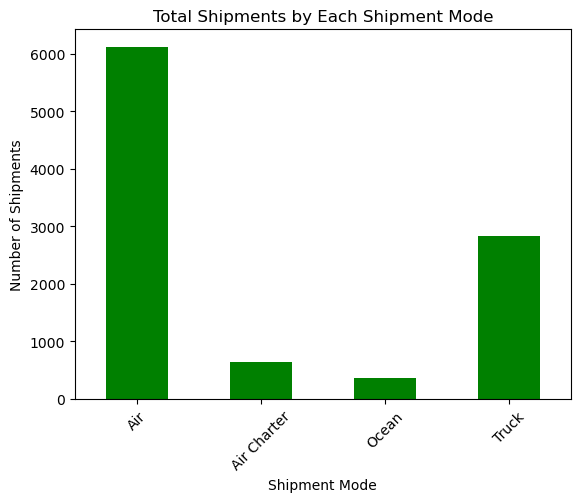

In [24]:
#14 Calculate the total number of shipments handled by each shipment mode and identify the shipment mode with the highest number of shipments.
shipment_mode_counts = df.groupby('Shipment Mode')['ID'].count()
print('Shipment Mode:', shipment_mode_counts.idxmax(), 'with number of', shipment_mode_counts.max(), 'shipments')

shipment_mode_counts.plot(kind='bar', color='green')
plt.title('Total Shipments by Each Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=45)
plt.show()

Product Group: ARV with total quantity of 185008389


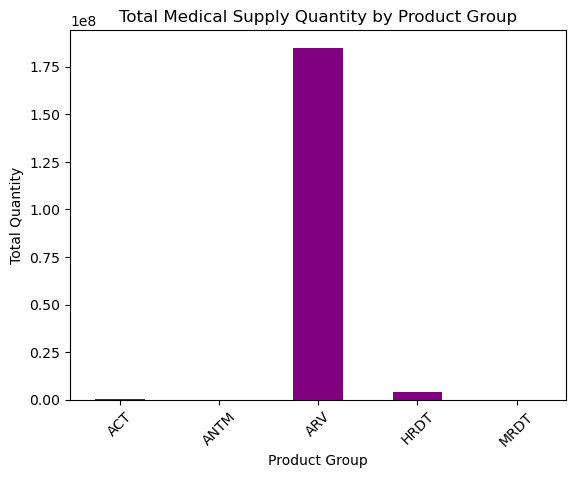

In [26]:
#15 Calculate the total quantity of medical supplies for each product group and identify the product group with the highest total quantity.
quantity_by_product = df.groupby('Product Group')['Line Item Quantity'].sum()
print('Product Group:', quantity_by_product.idxmax(), 'with total quantity of', quantity_by_product.max())

quantity_by_product.plot(kind='bar', color='purple')
plt.title('Total Medical Supply Quantity by Product Group')
plt.xlabel('Product Group')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.show()

Country with Highest Shipment Quantity: Nigeria
Highest Shipment Quantity: 33967950


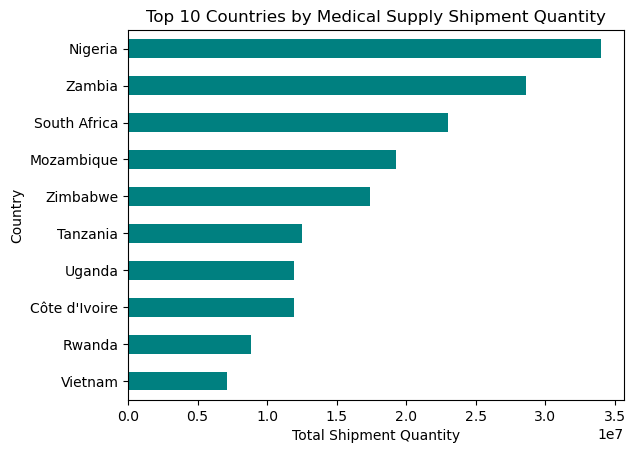

In [ ]:
#16 Identify the top 10 countries with the highest total medical supply shipment quantity.

# Calculate total shipment quantity for each country
quantity_by_country = df.groupby('Country')['Line Item Quantity'].sum()

# Select the top 10 countries
top_10_countries = quantity_by_country.sort_values(ascending=False).head(10)

print('Country with Highest Shipment Quantity:', top_10_countries.idxmax())
print('Highest Shipment Quantity:', top_10_countries.max())

# Visualize the results
top_10_countries.sort_values().plot(kind='barh', color='teal')

plt.title('Top 10 Countries by Medical Supply Shipment Quantity')
plt.xlabel('Total Shipment Quantity')
plt.ylabel('Country')
plt.show()

Shipment Mode             Air   Air Charter         Ocean         Truck
Weight_Category                                                        
Light             1414.438904  15281.138125   5843.616250   2183.185362
Medium            3522.621198  13530.673529  10980.123636   2686.107590
Heavy             6870.600900  12790.975676   4039.390769   4068.356860
Very Heavy       20171.471610  23869.402178  13482.745680  13353.022457


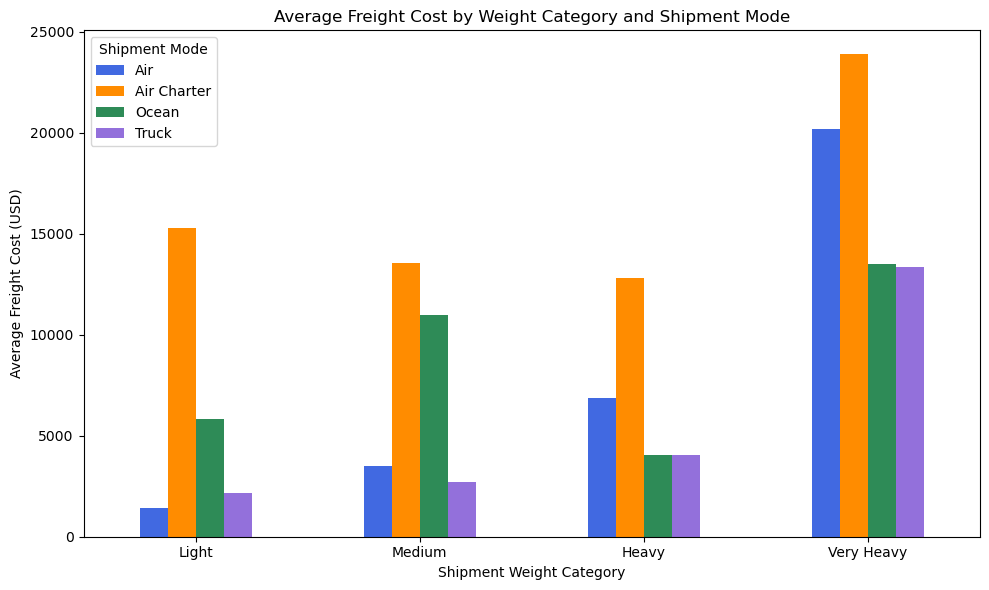

In [ ]:
#17 Compare the average freight cost across different shipment modes based on shipment weight categories.
# Create weight categories
df['Weight_Category'] = pd.cut(
    pd.to_numeric(df['Weight (Kilograms)'], errors='coerce'),
    bins=[0, 100, 500, 1000, float('inf')],
    labels=['Light', 'Medium', 'Heavy', 'Very Heavy']
)

# Convert freight cost to numeric
df['Freight Cost (USD)'] = pd.to_numeric(
    df['Freight Cost (USD)'].replace(r'[\$,]', '', regex=True),
    errors='coerce'
)

# Compare average freight cost by weight category and shipment mode
freight_comparison = df.pivot_table(
    index='Weight_Category',
    columns='Shipment Mode',
    values='Freight Cost (USD)',
    aggfunc='mean',
    observed=False
)

print(freight_comparison)

# Plot the comparison
freight_comparison.plot(
    kind='bar',
    color=['royalblue', 'darkorange', 'seagreen', 'mediumpurple'],
    figsize=(10, 6)
)

plt.title('Average Freight Cost by Weight Category and Shipment Mode')
plt.xlabel('Shipment Weight Category')
plt.ylabel('Average Freight Cost (USD)')
plt.xticks(rotation=0)
plt.legend(title='Shipment Mode')
plt.tight_layout()
plt.show()

Top 10 Medical Products by Total Value:
                                                    Line Item Value  \
Item Description                                                      
Lamivudine/Nevirapine/Zidovudine 150/200/300mg,...     2.837586e+08   
Efavirenz/Lamivudine/Tenofovir Disoproxil Fumar...     2.306398e+08   
Efavirenz 600mg, tablets, 30 Tabs                      1.375813e+08   
HIV 1/2, Determine Complete HIV Kit, 100 Tests         1.370223e+08   
Lamivudine/Zidovudine 150/300mg, tablets, 60 Tabs      1.282586e+08   
Efavirenz/Emtricitabine/Tenofovir Disoproxil Fu...     9.873090e+07   
Lamivudine/Tenofovir Disoproxil Fumarate 300/30...     6.576835e+07   
Lamivudine/Nevirapine/Stavudine 150/200/30mg, t...     5.664585e+07   
Nevirapine 200mg, tablets, 60 Tabs                     5.377274e+07   
Lopinavir/Ritonavir 200/50mg [Aluvia], tablets,...     5.001703e+07   

                                                    Line Item Quantity  
Item Description                  

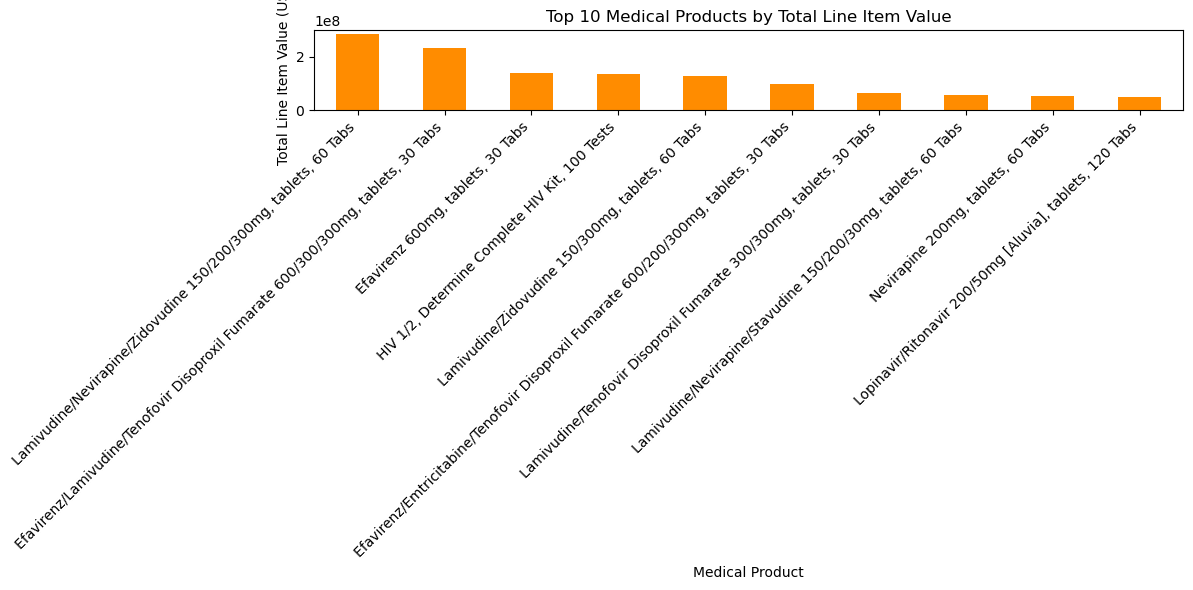

In [ ]:
#18 Identify the top 10 medical products with the highest total spending and compare their quantities.

# Calculate total value and quantity for each medical product
product_analysis = df.groupby('Item Description').agg({
    'Line Item Value': 'sum',
    'Line Item Quantity': 'sum'
})

# Select the top 10 products by total value
top_products = product_analysis.sort_values(
    by='Line Item Value', ascending=False
).head(10)

print("Top 10 Medical Products by Total Value:")
print(top_products)

# Plot total value and quantity separately
top_products['Line Item Value'].plot(
    kind='bar', color='darkorange', figsize=(12, 6)
)

plt.title('Top 10 Medical Products by Total Line Item Value')
plt.xlabel('Medical Product')
plt.ylabel('Total Line Item Value (USD)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Monthly Scheduled vs Actually Delivered Shipments:
    Scheduled Shipments  Actually Delivered
1                   716                 691
2                   719                 865
3                  1001                 972
4                   963                 891
5                   805                 855
6                   951                 927
7                   917                 872
8                  1081                1030
9                   884                 860
10                  822                 867
11                  785                 799
12                  680                 695


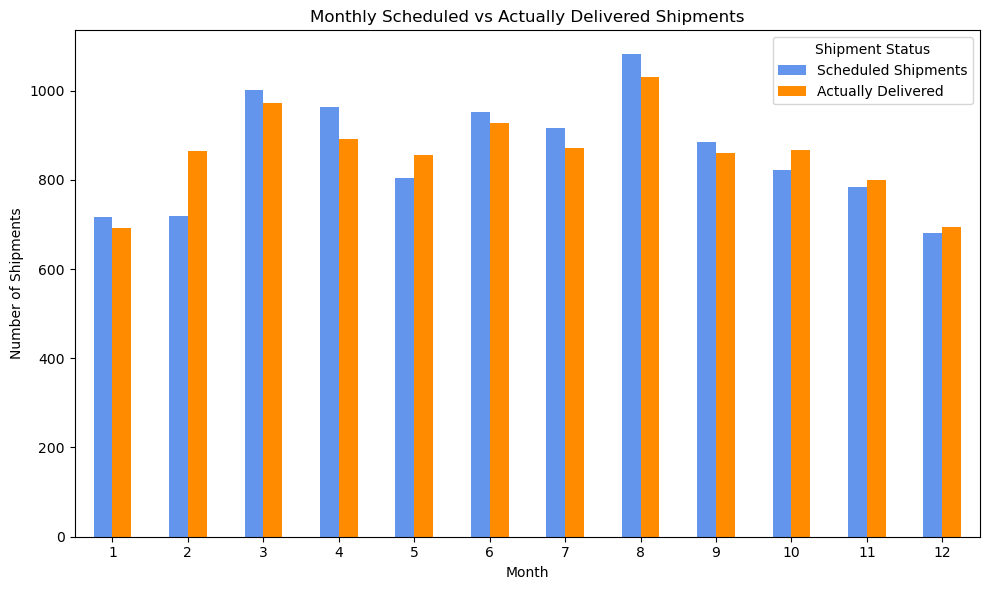

In [ ]:
#19 Compare the number of shipments scheduled and actually delivered in each month.
# Count shipments by scheduled delivery month
scheduled_shipments = df.groupby('Month')['ID'].count()

# Count shipments by actual delivery month
delivered_shipments = df.groupby('Delivered_Month')['ID'].count()

# Combine both results
monthly_comparison = pd.DataFrame({
    'Scheduled Shipments': scheduled_shipments,
    'Actually Delivered': delivered_shipments
}).fillna(0)

print("Monthly Scheduled vs Actually Delivered Shipments:")
print(monthly_comparison)

# Create a comparison graph
monthly_comparison.plot(
    kind='bar',
    color=['cornflowerblue', 'darkorange'],
    figsize=(10, 6)
)

plt.title('Monthly Scheduled vs Actually Delivered Shipments')
plt.xlabel('Month')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=0)
plt.legend(title='Shipment Status')
plt.tight_layout()
plt.show()

In [ ]:
#20 Identify the top 5 vendors supplying the greatest number of different medical products.

vendor_product_count = df.groupby('Vendor')['Item Description'].nunique()

# Identify the top 5 vendors
top_vendors = vendor_product_count.sort_values(ascending=False).head(5)

print("Top 5 Vendors by Number of Different Medical Products:")
print(top_vendors)

print("\nVendor Supplying the Most Different Products:")
print(top_vendors.idxmax())

print("\nNumber of Different Products:")
print(top_vendors.max())

Top 5 Vendors by Number of Different Medical Products:
Vendor
SCMS from RDC               92
S. BUYS WHOLESALER          60
Aurobindo Pharma Limited    43
CIPLA LIMITED               26
PHARMACY DIRECT             25
Name: Item Description, dtype: int64

Vendor Supplying the Most Different Products:
SCMS from RDC

Number of Different Products:
92


Monthly Scheduled Medical Supply Shipments:
Scheduled Delivery Date
2006-05-01      2
2006-06-01      2
2006-07-01      2
2006-08-01      6
2006-09-01     19
             ... 
2015-07-01    176
2015-08-01    103
2015-09-01     27
2015-10-01      1
2015-12-01      2
Length: 115, dtype: int64


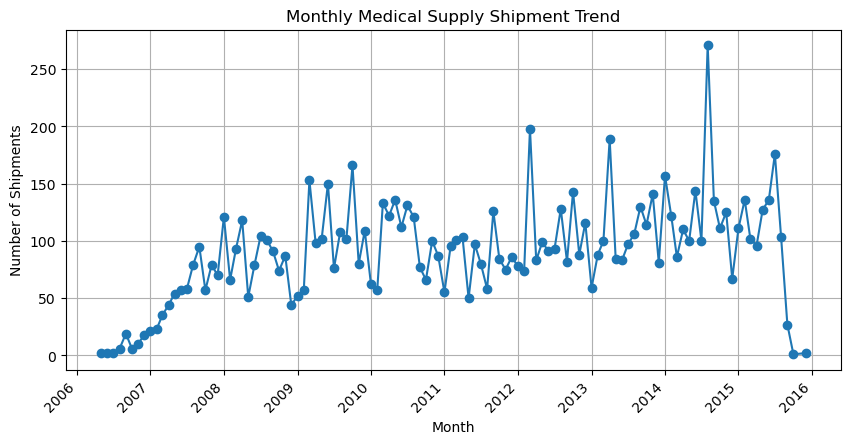

In [ ]:
#21 How does the number of scheduled medical supply shipments change over time?
df['Scheduled Delivery Date'] = pd.to_datetime(
    df['Scheduled Delivery Date'], errors='coerce'
)

monthly_shipments = (
    df.dropna(subset=['Scheduled Delivery Date'])
      .groupby(df['Scheduled Delivery Date'].dt.to_period('M'))
      .size()
)

monthly_shipments.index = monthly_shipments.index.to_timestamp()
print("Monthly Scheduled Medical Supply Shipments:")
print(monthly_shipments)

monthly_shipments.plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Monthly Medical Supply Shipment Trend')
plt.xlabel('Month')
plt.ylabel('Number of Shipments')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [ ]:
#22 Which manufacturing sites supply the highest number of different product groups, and how many different groups does each site supply?

# Count unique product groups supplied by each manufacturing site
site_product_groups = df.groupby('Manufacturing Site')['Product Group'].nunique()

# Display the top 10 manufacturing sites
top_sites = site_product_groups.sort_values(ascending=False).head(10)

print("Top 10 Manufacturing Sites by Product Group Diversity:")
print(top_sites)

print("\nManufacturing Site Supplying the Most Product Groups:")
print(top_sites.idxmax())

print("\nNumber of Different Product Groups:")
print(top_sites.max())

Top 10 Manufacturing Sites by Product Group Diversity:
Manufacturing Site
Not Applicable                           2
Standard Diagnostics, Korea              2
ABBSP                                    1
MSD, Haarlem, NL                         1
Micro Labs, Hosur, India                 1
Micro Labs Ltd. (Brown & Burk), India    1
Mepro Pharm Wadhwan Unit II              1
Medopharm Malur Factory, INDIA           1
Medochemie Factory A, CY                 1
Meditab (for Cipla) Daman IN             1
Name: Product Group, dtype: int64

Manufacturing Site Supplying the Most Product Groups:
Not Applicable

Number of Different Product Groups:
2


In [ ]:
#23 Which orders had either high freight costs or high order values?
# Convert freight cost to numeric
df['Freight Cost (USD)'] = pd.to_numeric(
    df['Freight Cost (USD)'], errors='coerce'
)

and_result_or = df[
    (df['Line Item Value'] > df['Line Item Value'].median()) |
    (df['Freight Cost (USD)'] > df['Freight Cost (USD)'].median())
]

print("Orders with High Order Value or High Freight Cost:")
print(and_result_or[
    ['Vendor', 'Line Item Value', 'Freight Cost (USD)']
].head(10))

print("Total Matching Orders:", len(and_result_or))

Orders with High Order Value or High Freight Cost:
                                               Vendor  Line Item Value  \
2                                Abbott GmbH & Co. KG         40000.00   
3   SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...        127360.80   
4                            Aurobindo Pharma Limited        121600.00   
5                            Aurobindo Pharma Limited          2225.60   
7                            Aurobindo Pharma Limited         60834.55   
9     ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)        115080.00   
10    ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)        115080.00   
11                               Trinity Biotech, Plc        100000.00   
13                                      CIPLA LIMITED         99800.00   
14                               Abbott GmbH & Co. KG         60000.00   

    Freight Cost (USD)  
2              1653.78  
3             16007.06  
4             45450.08  
5              5920.42  
7        

In [9]:
#24 Which medical supply orders have both high order quantities and high order values?
# Find orders with high quantity AND high order value

and_result = df[
    (df['Line Item Quantity'] > df['Line Item Quantity'].median()) &
    (df['Line Item Value'] > df['Line Item Value'].median())
]

print("Orders with High Quantity and High Order Value:")

print(and_result[
    ['Vendor', 'Product Group',
     'Line Item Quantity', 'Line Item Value']
].head(10))

print("Total Matching Orders:", len(and_result))

Orders with High Quantity and High Order Value:
                                               Vendor Product Group  \
3   SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...           ARV   
4                            Aurobindo Pharma Limited           ARV   
7                            Aurobindo Pharma Limited           ARV   
13                                      CIPLA LIMITED           ARV   
20                   CHEMBIO DIAGNOSTIC SYSTEMS, INC.          HRDT   
21                               BRISTOL-MYERS SQUIBB           ARV   
26                         Standard Diagnostics, Inc.          HRDT   
27                         Standard Diagnostics, Inc.          HRDT   
28                         Standard Diagnostics, Inc.          HRDT   
29                           Aurobindo Pharma Limited           ARV   

    Line Item Quantity  Line Item Value  
3                31920        127360.80  
4                38000        121600.00  
7                16667         60834.55  
13

Monthly Scheduled Shipments:
Scheduled Delivery Date
1      716
2      719
3     1001
4      963
5      805
6      951
7      917
8     1081
9      884
10     822
11     785
12     680
dtype: int64


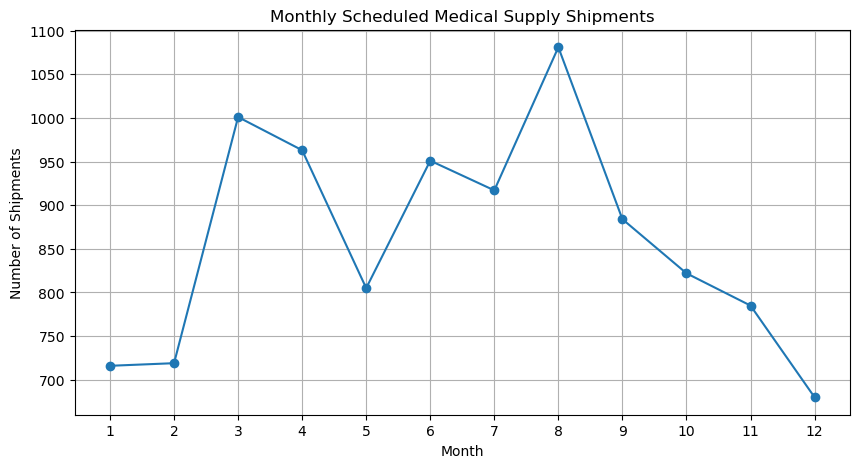

In [ ]:
#25 How does the number of scheduled medical supply shipments vary across different months?
df['Scheduled Delivery Date'] = pd.to_datetime(
    df['Scheduled Delivery Date'], errors='coerce'
)

monthly_shipments = (
    df.dropna(subset=['Scheduled Delivery Date'])
    .groupby(df['Scheduled Delivery Date'].dt.month)
    .size()
)

print("Monthly Scheduled Shipments:")
print(monthly_shipments)

monthly_shipments.plot(
    kind='line',
    marker='o',
    figsize=(10, 5)
)

plt.title('Monthly Scheduled Medical Supply Shipments')
plt.xlabel('Month')
plt.ylabel('Number of Shipments')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

Total Freight Cost by Shipment Mode:
Shipment Mode
Air            43038623.50
Truck          11865688.23
Air Charter     8926108.48
Ocean           3590728.79
Name: Freight Cost (USD), dtype: float64


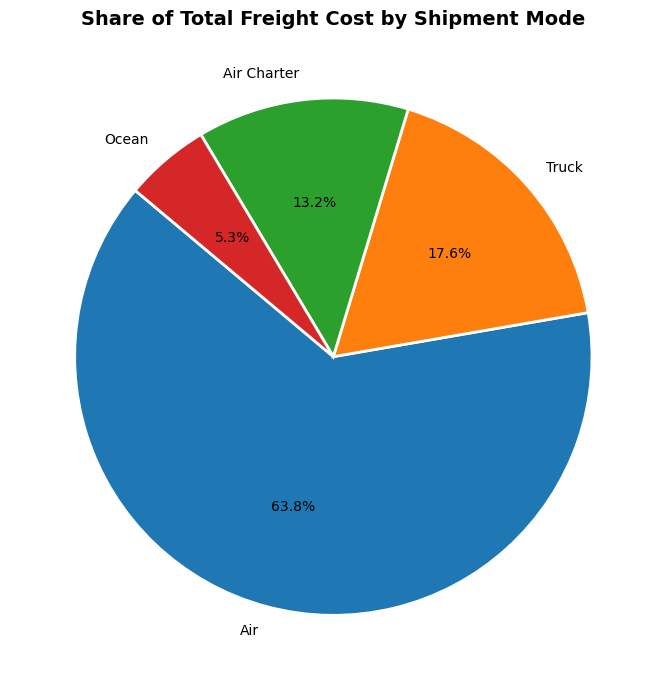

In [ ]:
#26 What is the percentage contribution of each shipment mode to total freight cost?
import pandas as pd
import matplotlib.pyplot as plt

# Convert freight cost to numeric values
df['Freight Cost (USD)'] = pd.to_numeric(
    df['Freight Cost (USD)'], errors='coerce'
)

# Calculate total freight cost by shipment mode
freight_by_mode = (
    df.dropna(subset=['Shipment Mode', 'Freight Cost (USD)'])
      .groupby('Shipment Mode')['Freight Cost (USD)']
      .sum()
      .sort_values(ascending=False)
)

# Display the summary
print("Total Freight Cost by Shipment Mode:")
print(freight_by_mode)

# Create pie chart
plt.figure(figsize=(9, 7))

freight_by_mode.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 10}
)

plt.title(
    'Share of Total Freight Cost by Shipment Mode',
    fontsize=14,
    fontweight='bold'
)
plt.ylabel('')
plt.tight_layout()
plt.show()

Number of Different Units of Measure: 31

Most Common Units of Measure:
60     4121
30     2630
100     976
240     670
120     474
Name: Unit of Measure (Per Pack), dtype: int64


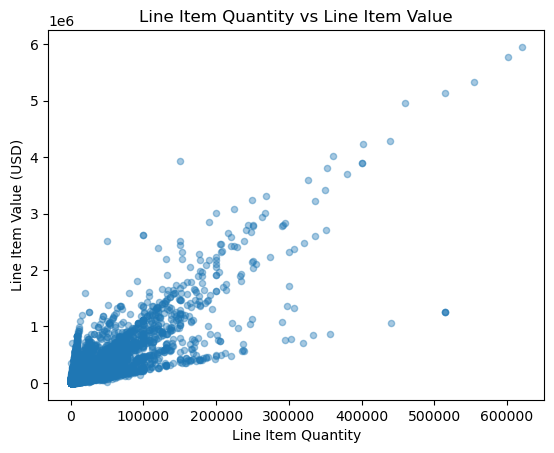

In [ ]:
#27 How does line item quantity vary with the unit of measure?
print("Number of Different Units of Measure:",
      df['Unit of Measure (Per Pack)'].nunique())

print("\nMost Common Units of Measure:")
print(df['Unit of Measure (Per Pack)'].value_counts().head())

df.plot(
    kind='scatter',
    x='Line Item Quantity',
    y='Line Item Value',
    alpha=0.4
)

plt.title('Line Item Quantity vs Line Item Value')
plt.xlabel('Line Item Quantity')
plt.ylabel('Line Item Value (USD)')
plt.show()

Correlation Matrix:
                                ID  Unit of Measure (Per Pack)  \
ID                          1.0000                     -0.0834   
Unit of Measure (Per Pack) -0.0834                      1.0000   
Line Item Quantity          0.1920                     -0.1510   
Line Item Value             0.1363                     -0.1287   
Pack Price                 -0.1687                      0.0972   
Unit Price                 -0.0733                     -0.1028   
Weight (Kilograms)          0.0724                     -0.0341   
Freight Cost (USD)          0.1080                     -0.0539   
Line Item Insurance (USD)   0.1036                     -0.1318   
year                        0.5658                     -0.0629   
Month                      -0.0057                      0.0035   
Day                         0.1563                     -0.0102   
Week_Number                -0.0116                      0.0019   
Delivered_Year              0.5662                     -

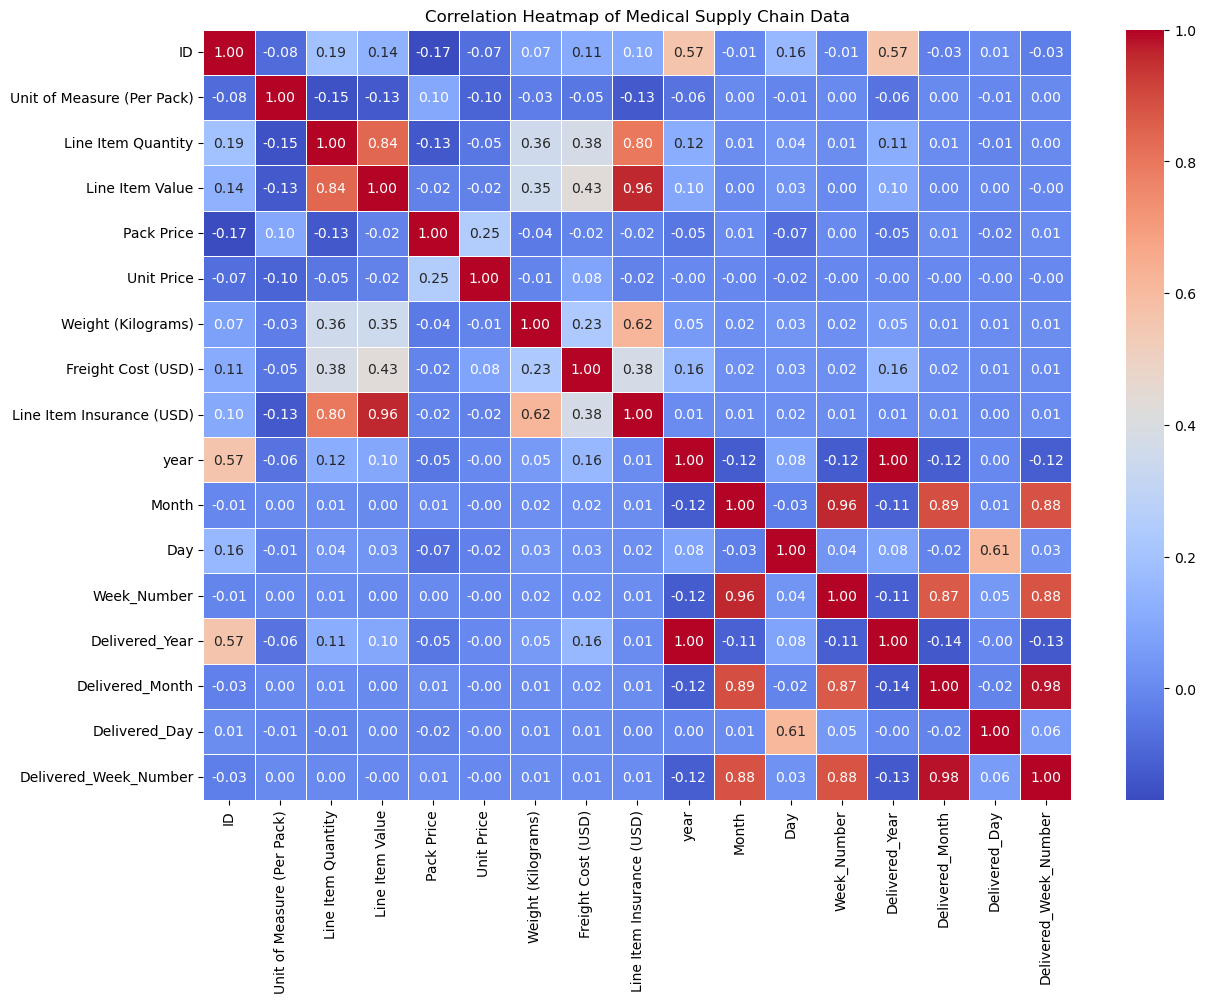

In [ ]:
#28 What is the correlation between numerical variables in the medical supply chain dataset?
# Select numerical columns
numerical_data = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

# Display correlation matrix
print("Correlation Matrix:")
print(correlation_matrix.round(4))

# Display correlation with Line Item Value
print("\nCorrelation with Line Item Value:")
print(correlation_matrix['Line Item Value'].sort_values(ascending=False))

# Display strongest relationship with Line Item Value
strongest = correlation_matrix['Line Item Value'].drop('Line Item Value').abs().idxmax()

print("\nStrongest Relationship:", strongest)
print("Correlation:", correlation_matrix.loc[strongest, 'Line Item Value'])

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Medical Supply Chain Data')
plt.show()

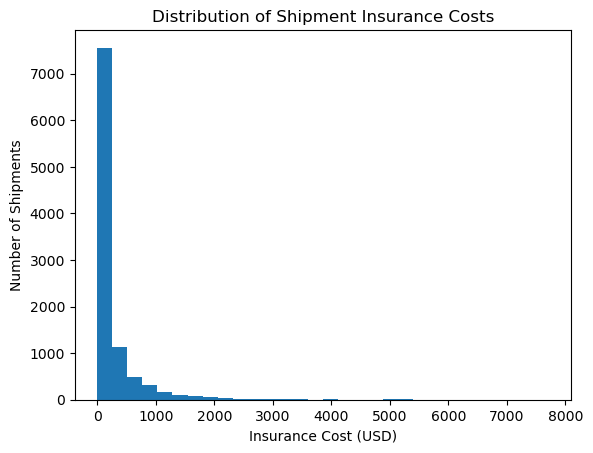

In [ ]:
#29 How is the distribution of shipment insurance costs across medical supply orders?
df['Line Item Insurance (USD)'].plot(kind='hist', bins=30)

plt.title('Distribution of Shipment Insurance Costs')
plt.xlabel('Insurance Cost (USD)')
plt.ylabel('Number of Shipments')
plt.show()

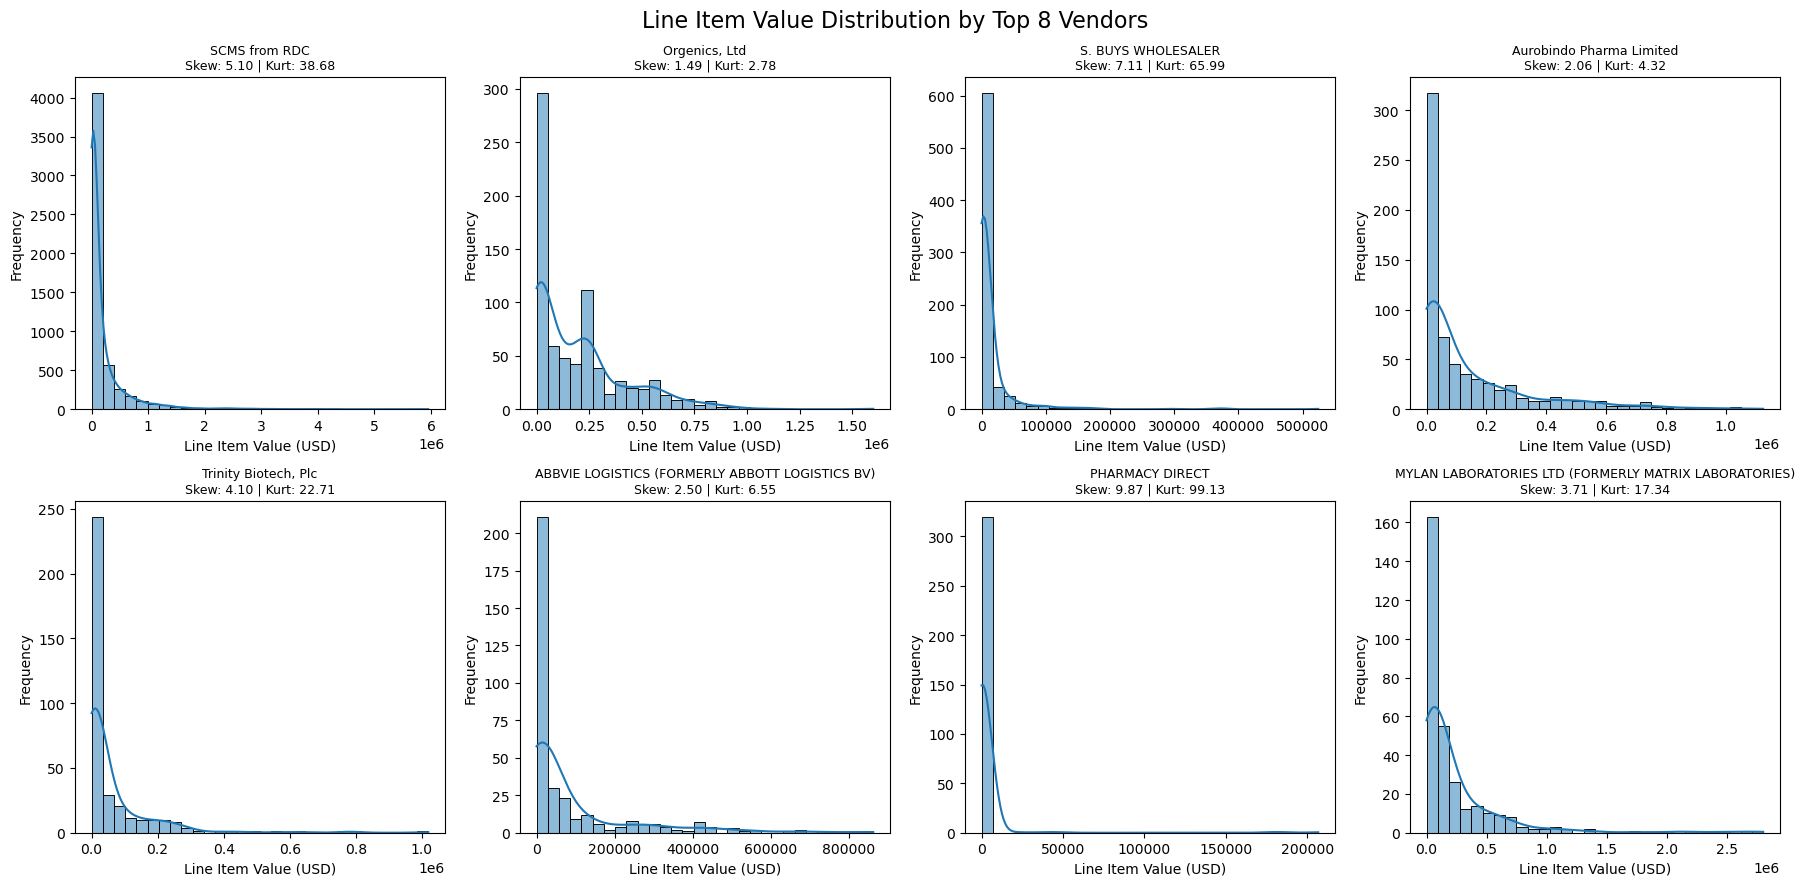

In [ ]:
#30 How does the distribution of line item values vary among the top 8 vendors, and what do skewness and kurtosis reveal about their distributions?
# Select top 8 vendors by number of orders
top_vendors = df['Vendor'].value_counts().head(8).index

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, vendor in enumerate(top_vendors):
    data = df.loc[df['Vendor'] == vendor, 'Line Item Value'].dropna()

    sns.histplot(data, bins=30, kde=True, ax=axes[i])

    skewness = data.skew()
    kurtosis = data.kurt()

    axes[i].set_title(
        f'{vendor}\nSkew: {skewness:.2f} | Kurt: {kurtosis:.2f}',
        fontsize=9
    )
    axes[i].set_xlabel('Line Item Value (USD)')
    axes[i].set_ylabel('Frequency')

plt.suptitle('Line Item Value Distribution by Top 8 Vendors', fontsize=16)
plt.tight_layout()
plt.show()

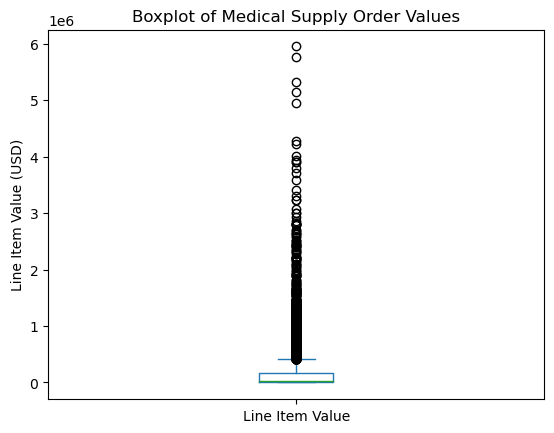

In [14]:
df['Line Item Value'].plot(kind='box')

plt.title('Boxplot of Medical Supply Order Values')
plt.ylabel('Line Item Value (USD)')
plt.show()

In [35]:
Q1 = df['Line Item Value'].quantile(0.25)
Q3 = df['Line Item Value'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Line Item Value'] < lower_bound) |
    (df['Line Item Value'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 4314.592500000001
Q3: 166447.13999999998
IQR: 162132.5475
Lower Bound: -238884.22874999998
Upper Bound: 409645.96124999993
Number of Outliers: 1127


In [36]:
high_value_outliers = df[df['Line Item Value'] > upper_bound]

print("High-Value Outliers:", len(high_value_outliers))
print("Percentage of Orders:", len(high_value_outliers) / len(df) * 100)

High-Value Outliers: 1127
Percentage of Orders: 10.916311507167764


## Outlier Detection

The IQR method was used to identify unusual values in `Line Item Value`.

- Q1 = 4,314.59 USD
- Q3 = 166,447.14 USD
- IQR = 162,132.55 USD
- Lower bound = −238,884.23 USD
- Upper bound = 409,645.96 USD
- High-value outliers = 1,127 orders
- High-value outliers = 10.92% of all orders

The analysis shows that some medical supply orders have unusually high item values. These observations were not removed because they may represent genuine large orders and can provide useful information for further analysis.

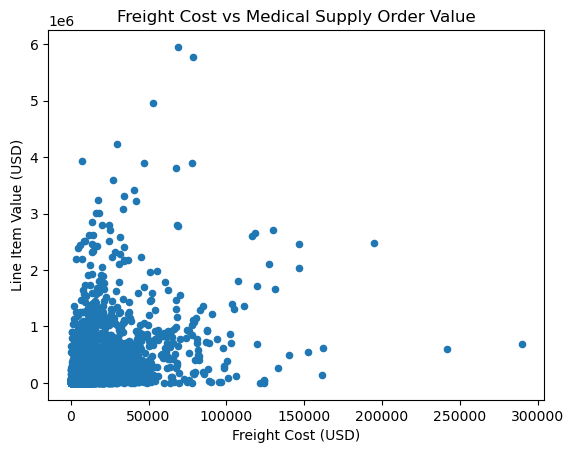

In [37]:
df.plot(
    kind='scatter',
    x='Freight Cost (USD)',
    y='Line Item Value'
)

plt.title('Freight Cost vs Medical Supply Order Value')
plt.xlabel('Freight Cost (USD)')
plt.ylabel('Line Item Value (USD)')
plt.show()

The scatter plot shows the relationship between freight cost and medical supply order value. It helps identify whether orders with higher item values tend to have higher freight costs. However, the distribution of points may indicate that other factors, such as shipment weight and shipment mode, also influence freight costs.

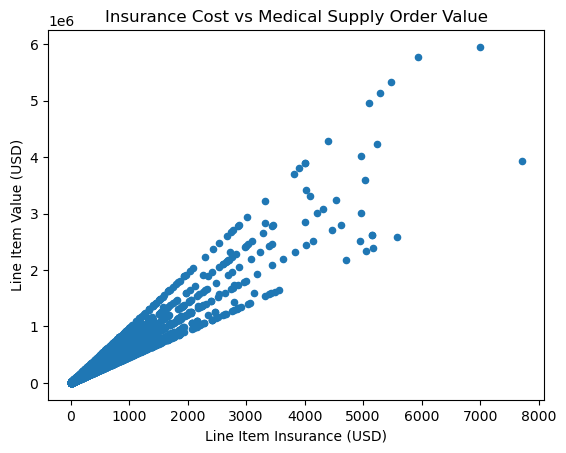

In [39]:
df.plot(
    kind='scatter',
    x='Line Item Insurance (USD)',
    y='Line Item Value'
)

plt.title('Insurance Cost vs Medical Supply Order Value')
plt.xlabel('Line Item Insurance (USD)')
plt.ylabel('Line Item Value (USD)')
plt.show()

The scatter plot shows the relationship between shipment insurance cost and medical supply order value. It helps examine whether orders with higher item values tend to have higher insurance costs. However, the relationship may also depend on shipment weight, product type, and other factors.

## Conclusion

This Exploratory Data Analysis was conducted to understand the patterns and factors associated with medical supply shipments, delivery performance, and transportation costs.

The analysis examined shipments across vendors, manufacturing sites, countries, product groups, shipment modes, scheduled delivery dates, and actual delivery dates. The results helped explore differences in shipment quantities, line item values, freight costs, insurance costs, and delivery delays across different categories.

The analysis also examined the relationships between shipment weight, pack price, order quantity, line item value, freight cost, and insurance cost. These comparisons helped explore how product and shipment characteristics may be associated with order values and transportation expenses.

Among the numerical variables, correlation analysis was used to examine relationships with line item value and other numerical variables. However, correlation indicates an association and does not prove causation.

The IQR analysis identified **1,127 unusually high line item values**, representing approximately **10.92% of all orders**. These observations were retained because they may represent genuine high-value medical supply orders and can provide useful information for further analysis.

Overall, this EDA helped identify important patterns in medical supply orders, delivery performance, and shipment costs. The findings provide a foundation for further statistical analysis and potential machine learning applications in medical supply chain management.